# 1. Data checks and basic EDA
Run the cells in order. We reuse the seed-42 dataset; this is a revised evaluation of data already examined during development.

We check the records, describe the dataset, and draw three simple comparisons. Class-based EDA uses earlier activity only, before day 120. The later test period is used in notebook 03.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "config/generator.yaml").exists(), "Open this notebook from the Research repository."
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
CONFIG = yaml.safe_load((ROOT / "config/generator.yaml").read_text())
OUT = ROOT / "report/core"
TABLES, FIGURES = OUT / "tables", OUT / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

## Prepare or reuse the banking records
The simulator and feature extractor remain reusable Python modules. Set `REGENERATE = True` only when intentionally rebuilding the data. This is not needed for an ordinary rerun of EDA.

In [2]:
from simulate import Simulator
from features import extract
DATA = ROOT / "data/synthetic"
DATA.mkdir(parents=True, exist_ok=True)
REGENERATE = False
if REGENERATE or not (DATA / "cardless_features.csv").exists():
    Simulator(CONFIG).run(str(DATA))
    extract(str(DATA), CONFIG).to_csv(DATA / "cardless_features.csv", index=False)
from core_evaluation import load_data
from validate import check_dataset
df = load_data(ROOT)
truth = pd.read_csv(DATA / "vouchers_truth.csv")

## Check the data
Each row below should have zero violations. These are practical checks of the simulated product and record consistency, not proof that the data represents real bank customers.

In [3]:
checks = check_dataset(df, truth, CONFIG)
checks.to_csv(TABLES / "data_checks.csv", index=False)
display(checks)
assert not checks.violations.any(), "Resolve the reported data problems before fitting models."

,check,violations
0,amount not a multiple of step,0
1,amount not positive,0
2,amount above max daily limit,0
3,amount above current limit,0
4,calendar-day total above max limit,0
5,calendar-month total above limit,0
6,redeemed but no delay,0
7,not redeemed but has delay,0
8,negative redemption delay,0
9,redeemed after expiry,0


In [4]:
summary = pd.DataFrame({"Item": ["Simulated customers", "Customers with vouchers", "Days", "Vouchers", "Legitimate vouchers", "Scam vouchers", "Scam share (%)", "Redeemed vouchers"],
    "Value": [CONFIG["n_customers"], df.customer_id.nunique(), CONFIG["days"], len(df), int((df.is_scam == 0).sum()), int(df.is_scam.sum()), round(100 * df.is_scam.mean(), 3), int(df.redeemed.sum())]})
summary.to_csv(TABLES / "dataset_summary.csv", index=False)
display(summary)
scenarios = df.groupby(["scenario_type", "is_scam"]).size().rename("vouchers").reset_index()
scenarios.to_csv(TABLES / "dataset_scenarios.csv", index=False)
display(scenarios)

,Item,Value
0,Simulated customers,20000.000
1,Customers with vouchers,19078.000
2,Days,180.000
3,Vouchers,216147.000
4,Legitimate vouchers,213386.000
5,Scam vouchers,2761.000
6,Scam share (%),1.277
7,Redeemed vouchers,209222.000


,scenario_type,is_scam,vouchers
0,legit_emergency,0,783
1,legit_new_phone,0,1557
2,legit_travel,0,855
3,normal,0,210191
4,scam_classic,1,653
5,scam_limit_raise,1,425
6,scam_self_send,1,447
7,scam_split,1,904
8,scam_subtle,1,332


## Select earlier activity for class comparisons
Creation-time plots use vouchers created before day 120. Redemption plots use vouchers cashed out before that boundary. Summaries above describe the full dataset; these plots avoid using later class differences to redesign the models.

In [5]:
start = pd.Timestamp(CONFIG["start_date"])
test_start = start + pd.Timedelta(days=120)
earlier = df[df.created_at < test_start].copy()
earlier_cashouts = df[(df.redeemed == 1) & (df.redeemed_at < test_start)].copy()
import matplotlib.pyplot as plt
from core_evaluation import save_figure
COLORS = ["#2878B5", "#E66B37"]
CLASS_NAMES = ["Legitimate", "Scam"]
medians = earlier.groupby("is_scam")[["amount", "amount_ratio_to_avg_90d"]].median().rename(index={0:"Legitimate", 1:"Scam"})
display(medians)
medians.to_csv(TABLES / "eda_amount_medians.csv")

,amount,amount_ratio_to_avg_90d
is_scam,,
Legitimate,600.0,1.000
Scam,1800.0,1.684


## Plot 1: voucher amounts
Each class is shown as percentages of its own vouchers. Both use identical amount ranges. This lets us compare patterns despite having many more legitimate transactions.

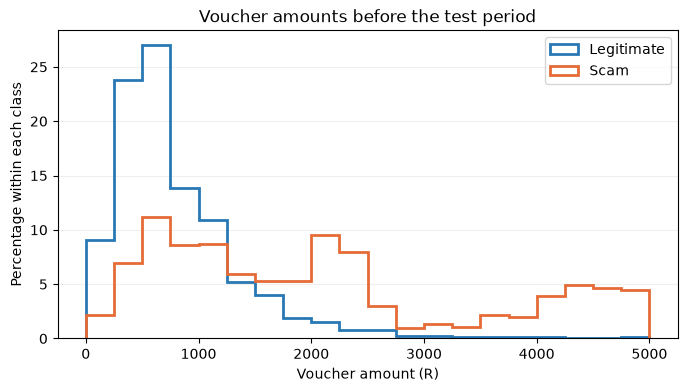

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, CONFIG["product"]["max_daily_limit"] + 250, 250)
for label in (0, 1):
    values = earlier.loc[earlier.is_scam == label, "amount"]
    ax.hist(values, bins=bins, weights=np.full(len(values), 100 / len(values)), histtype="step", linewidth=2, color=COLORS[label], label=CLASS_NAMES[label])
ax.set(xlabel="Voucher amount (R)", ylabel="Percentage within each class", title="Voucher amounts before the test period")
ax.legend(); ax.grid(axis="y", alpha=.2)
save_figure(fig, FIGURES, "eda_amounts")
plt.show()

## Plot 2: time until cash-out
The final group includes all delays of six hours or more, so long delays are not hidden. Fast redemption can occur in both legitimate activity and scams.

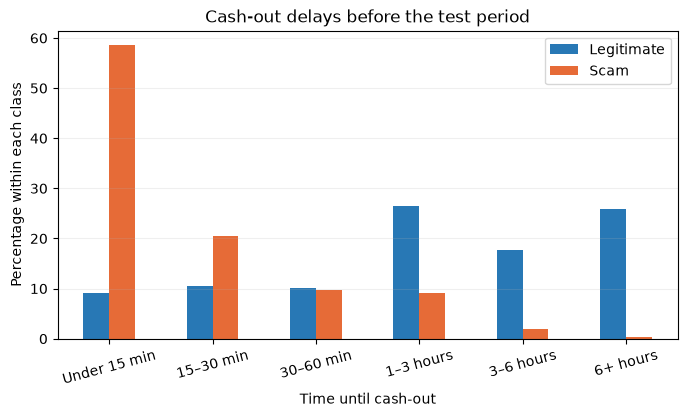

In [7]:
labels = ["Under 15 min", "15–30 min", "30–60 min", "1–3 hours", "3–6 hours", "6+ hours"]
delays = earlier_cashouts.assign(delay_group=pd.cut(earlier_cashouts.redeem_delay_min, [0,15,30,60,180,360,np.inf], labels=labels, right=False))
counts = pd.crosstab(delays.delay_group, delays.is_scam).reindex(labels, fill_value=0)
percent = counts.div(counts.sum(axis=0), axis=1) * 100
percent.columns = CLASS_NAMES
percent.to_csv(TABLES / "eda_redemption_delays.csv")
fig, ax = plt.subplots(figsize=(8,4))
percent.plot.bar(ax=ax, color=COLORS, rot=15)
ax.set(xlabel="Time until cash-out", ylabel="Percentage within each class", title="Cash-out delays before the test period")
ax.grid(axis="y", alpha=.2)
save_figure(fig, FIGURES, "eda_cashout_delays")
plt.show()

## Plot 3: common warning indicators
These are observed percentages, not the probabilities used to generate the scenarios. A warning sign can be present in a legitimate voucher too.

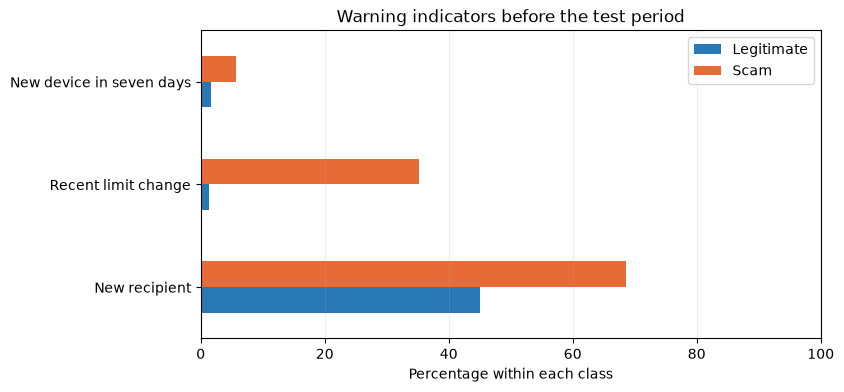

In [8]:
flags = pd.DataFrame({"New recipient": 1-earlier.recipient_known, "Recent limit change": earlier.limit_changed_24h, "New device in seven days": earlier.new_device_7d, "is_scam": earlier.is_scam})
rates = flags.groupby("is_scam").mean().T * 100
rates.columns = CLASS_NAMES
rates.to_csv(TABLES / "eda_warning_indicators.csv")
fig, ax = plt.subplots(figsize=(8,4))
rates.plot.barh(ax=ax, color=COLORS)
ax.set(xlabel="Percentage within each class", ylabel="", title="Warning indicators before the test period", xlim=(0,100))
ax.grid(axis="x", alpha=.2)
save_figure(fig, FIGURES, "eda_warning_indicators")
plt.show()

## Record what these checks establish
The files are internally consistent if the checks pass. The plots show where the simulated classes differ and overlap. They do not establish real bank performance. Do not change the scenario probabilities to make a detector perform better. Continue with notebook 02.